In [2]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit import transpile
from qiskit.providers.basic_provider import BasicProvider
from itertools import product
import numpy as np
from qiskit_ibm_runtime.fake_provider import FakeGuadalupeV2


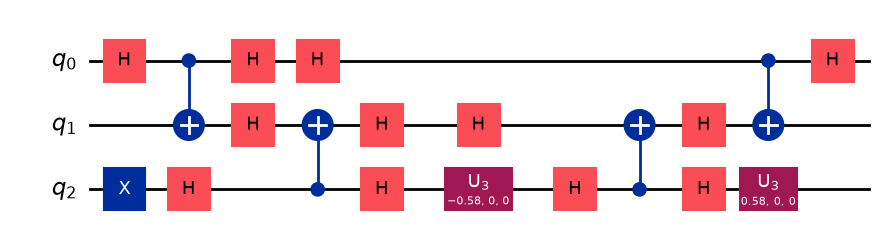

Statevector([-2.74011968e-01+0.j,  2.74011968e-01+0.j, -3.99429390e-18+0.j,
              5.07856061e-18+0.j,  9.18231325e-01+0.j,  8.17686750e-02+0.j,
             -6.71741673e-18+0.j, -2.74495362e-17+0.j],
            dims=(2, 2, 2))
Cirquit depth: 11
Operation counts: OrderedDict([('h', 12), ('cx', 4), ('u3', 2), ('x', 1)])
[CircuitInstruction(operation=Instruction(name='h', num_qubits=1, num_clbits=0, params=[]), qubits=(<Qubit register=(3, "q"), index=0>,), clbits=()), CircuitInstruction(operation=Instruction(name='x', num_qubits=1, num_clbits=0, params=[]), qubits=(<Qubit register=(3, "q"), index=2>,), clbits=()), CircuitInstruction(operation=Instruction(name='cx', num_qubits=2, num_clbits=0, params=[]), qubits=(<Qubit register=(3, "q"), index=0>, <Qubit register=(3, "q"), index=1>), clbits=()), CircuitInstruction(operation=Instruction(name='h', num_qubits=1, num_clbits=0, params=[]), qubits=(<Qubit register=(3, "q"), index=0>,), clbits=()), CircuitInstruction(operation=Instructi

In [5]:

qc = QuantumCircuit.from_qasm_file("/Users/nirvanfernando/Desktop/QHD:QC/qhd/lab3/qasm_files/linearsolver.qasm"
)

display(qc.draw("mpl", fold=-1))
sv = Statevector.from_instruction(qc)
print(sv)

print("Cirquit depth:", qc.depth())
print("Operation counts:", qc.count_ops())
print(qc.data)


In [24]:
# copy the circuit:
qc_m = qc.copy()

# Add measurement:
qc_m.measure_all()

backend = BasicProvider().get_backend("basic_simulator")
result = backend.run(
    transpile(qc_m, backend),
    shots=1024
).result()

counts = result.get_counts()
print("Counts:", counts)

num_qubits = qc.num_qubits

all_states = [
    "".join(state)
    for state in product("01", repeat=num_qubits)
]

total_shots = sum(counts.values())

probabilities = [
    counts.get(state, 0) / total_shots
    for state in all_states
]

print(probabilities)

Counts: {'1000000010': 1024}
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 

In [65]:
def Fidelity(psi, phi):
    F = np.abs(np.vdot(psi, phi))**2
    return float(np.clip(F, 0.0, 1.0))


# Original statevector
sv_original = Statevector(qc)

for optimization_level in [0, 1, 2, 3]:

    qc_t = transpile(
        qc,
        basis_gates=['id', 'ry', 'rx', 'rz', 'cx'],
        optimization_level=optimization_level
    )

    # Compiled statevector
    sv_t = Statevector(qc_t)

    # Fidelity
    fidelity = Fidelity(sv_original.data, sv_t.data)

    print(f"\nOptimization level: {optimization_level}")
    print(f"Fidelity: {fidelity}")
    print(f"Depth: {qc_t.depth()}")
    print(f"Gate count: {qc_t.count_ops()}")


Optimization level: 0
Fidelity: 0.9999999999999976
Depth: 111
Gate count: OrderedDict([('cx', 65), ('rz', 56), ('rx', 21), ('ry', 16)])

Optimization level: 1
Fidelity: 0.9999999999999987
Depth: 107
Gate count: OrderedDict([('cx', 65), ('rz', 56), ('ry', 16), ('rx', 13)])

Optimization level: 2
Fidelity: 0.9999999999999987
Depth: 107
Gate count: OrderedDict([('cx', 65), ('rz', 52), ('ry', 16), ('rx', 13)])

Optimization level: 3
Fidelity: 0.9999999999999987
Depth: 107
Gate count: OrderedDict([('cx', 65), ('rz', 52), ('ry', 16), ('rx', 13)])


In [10]:
backend = FakeGuadalupeV2()
result = backend.run(
    transpile(qc, backend),
    shots=1024
).result()

counts = result.get_counts()
print("Counts:", counts)

num_qubits = qc.num_qubits

all_states = [
    "".join(state)
    for state in product("01", repeat=num_qubits)
]

total_shots = sum(counts.values())

probabilities = [
    counts.get(state, 0) / total_shots
    for state in all_states
]

print(probabilities)

NameError: name 'qc' is not defined